# Transformasi Geometris Citra
**Nama :** Abdillah Ahmad
**NIM  :** G.211.24.0094

Tujuh transformasi geometris pada citra grayscale:
1. Translasi  2. Rotasi  3. Scaling  4. Shearing  5. Refleksi  6. Affine  7. Proyektif (Perspective)

**Ketentuan:** input dibaca dari folder dataset (minimal 20 citra, diseragamkan ukurannya), dikonversi ke grayscale, output berupa citra hasil transformasi yang ditampilkan dan disimpan.

## 1. Import Library & Mount Google Drive

In [48]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Mount Google Drive (dilewati otomatis jika bukan di Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Bukan di Google Colab, mount Drive dilewati.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Konfigurasi


In [49]:
FOLDER_DATASET = "/content/dataset_astronout"
FOLDER_OUTPUT  = "hasil_transformasi"
UKURAN_CITRA   = (256, 256)   # (lebar, tinggi) -> semua citra diseragamkan ke ukuran ini
MINIMAL_CITRA  = 20
EKSTENSI       = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

if os.environ.get("FOLDER_DATASET"):      # opsional: override lewat environment variable
    FOLDER_DATASET = os.environ["FOLDER_DATASET"]

## 3. Fungsi Membaca Dataset & Konversi Grayscale

In [50]:
def baca_dataset(folder, ukuran=UKURAN_CITRA, minimal=MINIMAL_CITRA):
    """
    Membaca semua citra dalam folder, mengonversi ke grayscale,
    dan menyeragamkan ukurannya.

    Return: list of (nama_file, citra_grayscale)
    """
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Folder dataset tidak ditemukan: {folder}")

    daftar_file = sorted(f for f in os.listdir(folder) if f.lower().endswith(EKSTENSI))
    dataset = []
    for nama in daftar_file:
        img = cv2.imread(os.path.join(folder, nama))
        if img is None:
            print(f"Lewati (gagal dibaca): {nama}")
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)            # konversi ke grayscale
        gray = cv2.resize(gray, ukuran, interpolation=cv2.INTER_AREA)  # samakan ukuran
        dataset.append((nama, gray))

    if len(dataset) < minimal:
        raise ValueError(f"Dataset hanya berisi {len(dataset)} citra, minimal {minimal} citra.")

    print(f"Berhasil membaca {len(dataset)} citra, ukuran {ukuran[0]}x{ukuran[1]}, grayscale.")
    return dataset

## 4. Fungsi Transformasi Geometris

### 4.1 Translasi
Matriks: $\begin{bmatrix}1 & 0 & t_x\\0 & 1 & t_y\end{bmatrix}$

In [51]:
def translasi(img, tx=50, ty=30):
    """Menggeser citra sejauh tx (horizontal) dan ty (vertikal) piksel."""
    h, w = img.shape[:2]
    M = np.float32([[1, 0, tx],
                    [0, 1, ty]])
    return cv2.warpAffine(img, M, (w, h))

### 4.2 Rotasi
Memutar citra sebesar θ derajat terhadap titik pusat (positif = berlawanan arah jarum jam).

In [52]:
def rotasi(img, sudut=45, skala=1.0, pusat=None):
    """Memutar citra sebesar `sudut` derajat terhadap titik pusat citra."""
    h, w = img.shape[:2]
    if pusat is None:
        pusat = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, skala)
    return cv2.warpAffine(img, M, (w, h))

### 4.3 Scaling (Perbesaran / Pengecilan)
Matriks: $\begin{bmatrix}s_x & 0 & 0\\0 & s_y & 0\end{bmatrix}$. `fx, fy > 1` memperbesar, `< 1` memperkecil.

In [53]:
def scaling(img, fx=1.5, fy=1.5):
    """Mengubah ukuran citra dengan faktor fx (lebar) dan fy (tinggi)."""
    interpolasi = cv2.INTER_AREA if (fx < 1 and fy < 1) else cv2.INTER_LINEAR
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interpolasi)

### 4.4 Shearing (Skewing)
Matriks: $\begin{bmatrix}1 & sh_x & 0\\sh_y & 1 & 0\end{bmatrix}$. Kanvas diperlebar agar citra tidak terpotong.

In [54]:
def shearing(img, shx=0.3, shy=0.0):
    """Memiringkan citra: shx = shear horizontal, shy = shear vertikal."""
    h, w = img.shape[:2]
    M = np.float32([[1,   shx, 0],
                    [shy, 1,   0]])
    # geser agar hasil tidak keluar kanvas bila shear bernilai negatif
    M[0, 2] = -shx * h if shx < 0 else 0
    M[1, 2] = -shy * w if shy < 0 else 0
    lebar_baru  = int(w + abs(shx) * h)
    tinggi_baru = int(h + abs(shy) * w)
    return cv2.warpAffine(img, M, (lebar_baru, tinggi_baru))

### 4.5 Refleksi (Reflection)
`arah`: `'horizontal'` (cermin kiri-kanan), `'vertikal'` (atas-bawah), `'keduanya'`.

In [55]:
def refleksi(img, arah="horizontal"):
    """Mencerminkan citra terhadap sumbu tertentu."""
    kode = {"vertikal": 0, "horizontal": 1, "keduanya": -1}
    if arah not in kode:
        raise ValueError("arah harus 'horizontal', 'vertikal', atau 'keduanya'")
    return cv2.flip(img, kode[arah])

### 4.6 Transformasi Affine
Ditentukan oleh 3 pasang titik (sumber → tujuan). Garis sejajar tetap sejajar.

In [56]:
def transformasi_affine(img, pts_asal=None, pts_tujuan=None):
    """Transformasi affine berdasarkan 3 titik asal dan 3 titik tujuan."""
    h, w = img.shape[:2]
    if pts_asal is None:
        pts_asal = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])
    if pts_tujuan is None:
        pts_tujuan = np.float32([[0, h * 0.25], [w * 0.85, h * 0.10], [w * 0.15, h * 0.90]])
    M = cv2.getAffineTransform(np.float32(pts_asal), np.float32(pts_tujuan))
    return cv2.warpAffine(img, M, (w, h))

### 4.7 Transformasi Proyektif (Perspective)
Ditentukan oleh 4 pasang titik. Garis sejajar bisa menjadi tidak sejajar (efek sudut pandang 3D).

In [57]:
def transformasi_proyektif(img, pts_asal=None, pts_tujuan=None):
    """Transformasi perspektif berdasarkan 4 titik asal dan 4 titik tujuan."""
    h, w = img.shape[:2]
    if pts_asal is None:
        pts_asal = np.float32([[0, 0], [w - 1, 0], [0, h - 1], [w - 1, h - 1]])
    if pts_tujuan is None:
        pts_tujuan = np.float32([[w * 0.20, h * 0.10], [w * 0.80, h * 0.10],
                                 [0, h - 1],           [w - 1, h - 1]])
    M = cv2.getPerspectiveTransform(np.float32(pts_asal), np.float32(pts_tujuan))
    return cv2.warpPerspective(img, M, (w, h))

## 5. Fungsi Gabungan: Terapkan Semua Transformasi

In [58]:
def transformasi_geometris(img):
    """Menerapkan ketujuh transformasi pada satu citra grayscale. Return: dict {nama: citra}"""
    return {
        "1_Translasi":       translasi(img, tx=50, ty=30),
        "2_Rotasi":          rotasi(img, sudut=45),
        "3a_Scaling_Besar":  scaling(img, fx=1.5, fy=1.5),
        "3b_Scaling_Kecil":  scaling(img, fx=0.5, fy=0.5),
        "4_Shearing":        shearing(img, shx=0.3, shy=0.0),
        "5_Refleksi":        refleksi(img, arah="horizontal"),
        "6_Affine":          transformasi_affine(img),
        "7_Proyektif":       transformasi_proyektif(img),
    }


def proses_dataset(dataset, folder_output=FOLDER_OUTPUT):
    """Mentransformasi seluruh citra dataset dan menyimpan hasilnya per jenis transformasi."""
    semua_hasil = {}
    for nama, gray in dataset:
        hasil = transformasi_geometris(gray)
        semua_hasil[nama] = hasil
        for jenis, citra in hasil.items():
            folder = os.path.join(folder_output, jenis)
            os.makedirs(folder, exist_ok=True)
            cv2.imwrite(os.path.join(folder, nama), citra)
    print(f"{len(dataset)} citra x {len(semua_hasil[dataset[0][0]])} transformasi "
          f"tersimpan di folder '{folder_output}'.")
    return semua_hasil

## 6. Fungsi Menampilkan Hasil

In [59]:
def tampilkan_satu_citra(nama, asli, hasil):
    """Menampilkan citra asli dan semua hasil transformasinya dalam satu grid."""
    gambar = [("Asli (Grayscale)", asli)] + list(hasil.items())
    kolom = 3
    baris = int(np.ceil(len(gambar) / kolom))
    plt.figure(figsize=(12, 4 * baris))
    for i, (judul, im) in enumerate(gambar):
        plt.subplot(baris, kolom, i + 1)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(f"{judul}\n{im.shape[1]}x{im.shape[0]}", fontsize=10)
        plt.axis("off")
    plt.suptitle(f"Transformasi Geometris: {nama}", fontsize=14)
    plt.tight_layout()
    plt.show()


def tampilkan_per_transformasi(dataset, semua_hasil, jenis, kolom=5):
    """Menampilkan satu jenis transformasi untuk seluruh citra dataset."""
    n = len(dataset)
    baris = int(np.ceil(n / kolom))
    plt.figure(figsize=(2.6 * kolom, 2.8 * baris))
    for i, (nama, _) in enumerate(dataset):
        plt.subplot(baris, kolom, i + 1)
        plt.imshow(semua_hasil[nama][jenis], cmap="gray", vmin=0, vmax=255)
        plt.title(nama, fontsize=8)
        plt.axis("off")
    plt.suptitle(f"{jenis} - {n} citra", fontsize=14)
    plt.tight_layout()
    plt.show()

## 7. Eksekusi Program

### 7.1 Baca dataset (≥ 20 citra) & konversi grayscale

Berhasil membaca 20 citra, ukuran 256x256, grayscale.


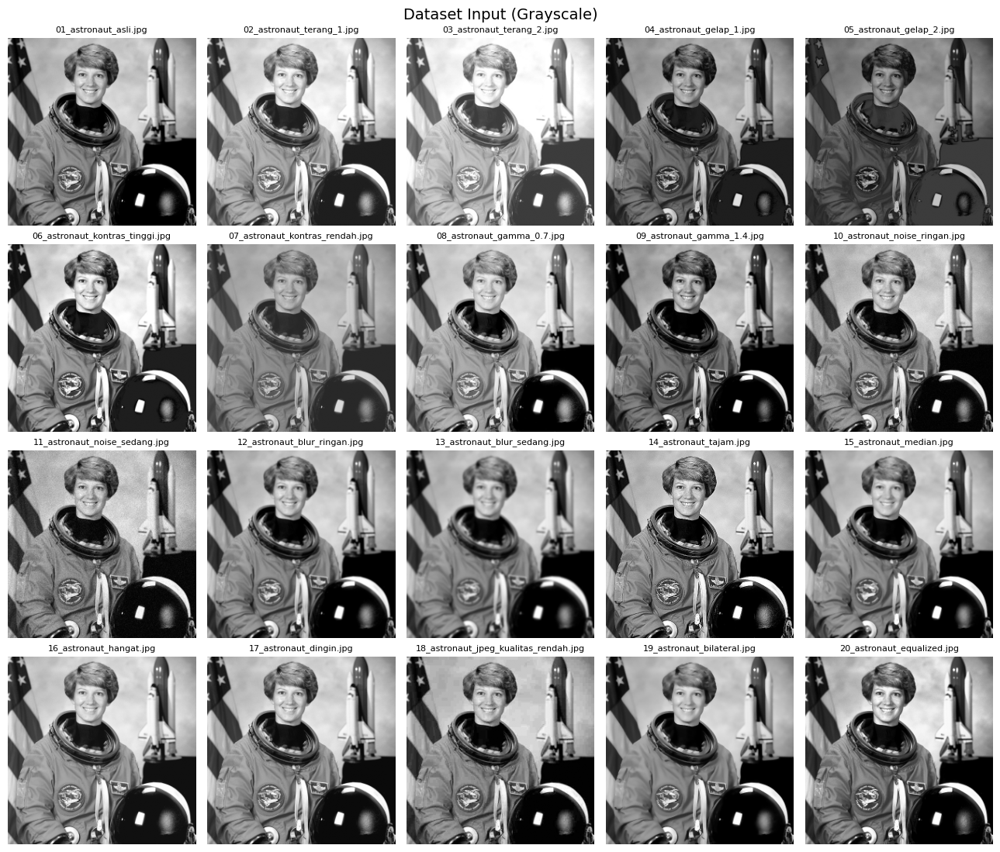

In [60]:
dataset = baca_dataset(FOLDER_DATASET)

# Tampilkan semua citra input (grayscale)
plt.figure(figsize=(13, 2.8 * int(np.ceil(len(dataset) / 5))))
for i, (nama, gray) in enumerate(dataset):
    plt.subplot(int(np.ceil(len(dataset) / 5)), 5, i + 1)
    plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
    plt.title(nama, fontsize=8)
    plt.axis("off")
plt.suptitle("Dataset Input (Grayscale)", fontsize=14)
plt.tight_layout()
plt.show()

### 7.2 Transformasikan seluruh citra & simpan hasil

In [61]:
semua_hasil = proses_dataset(dataset)

20 citra x 8 transformasi tersimpan di folder 'hasil_transformasi'.


### 7.3 Contoh: semua transformasi pada citra pertama

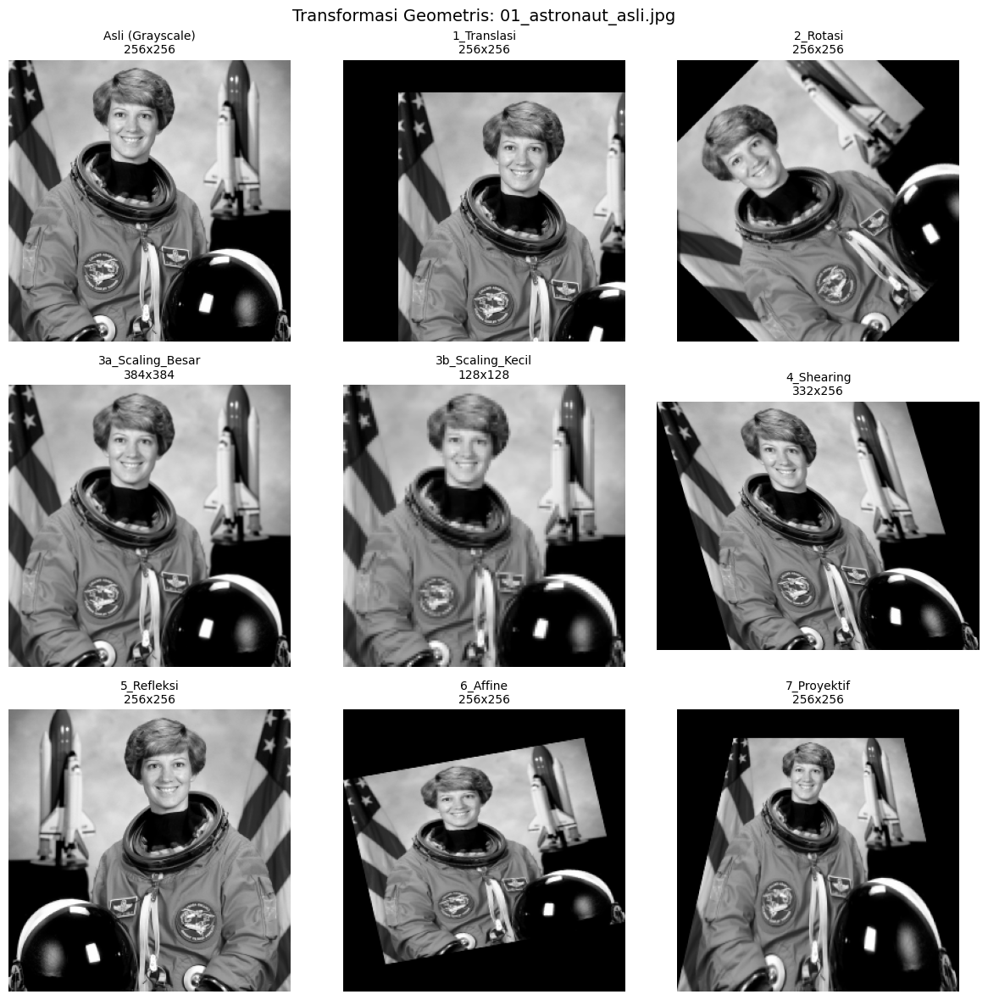

In [62]:
nama0, gray0 = dataset[0]
tampilkan_satu_citra(nama0, gray0, semua_hasil[nama0])

### 7.4 Hasil tiap transformasi untuk seluruh dataset

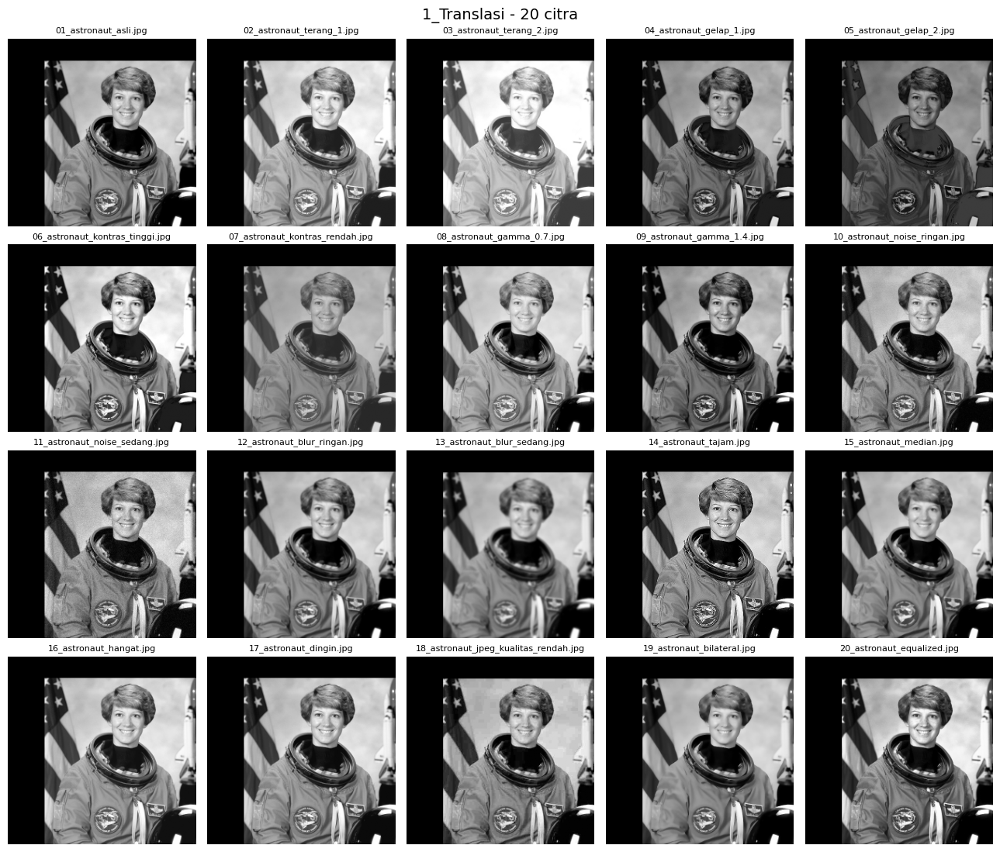

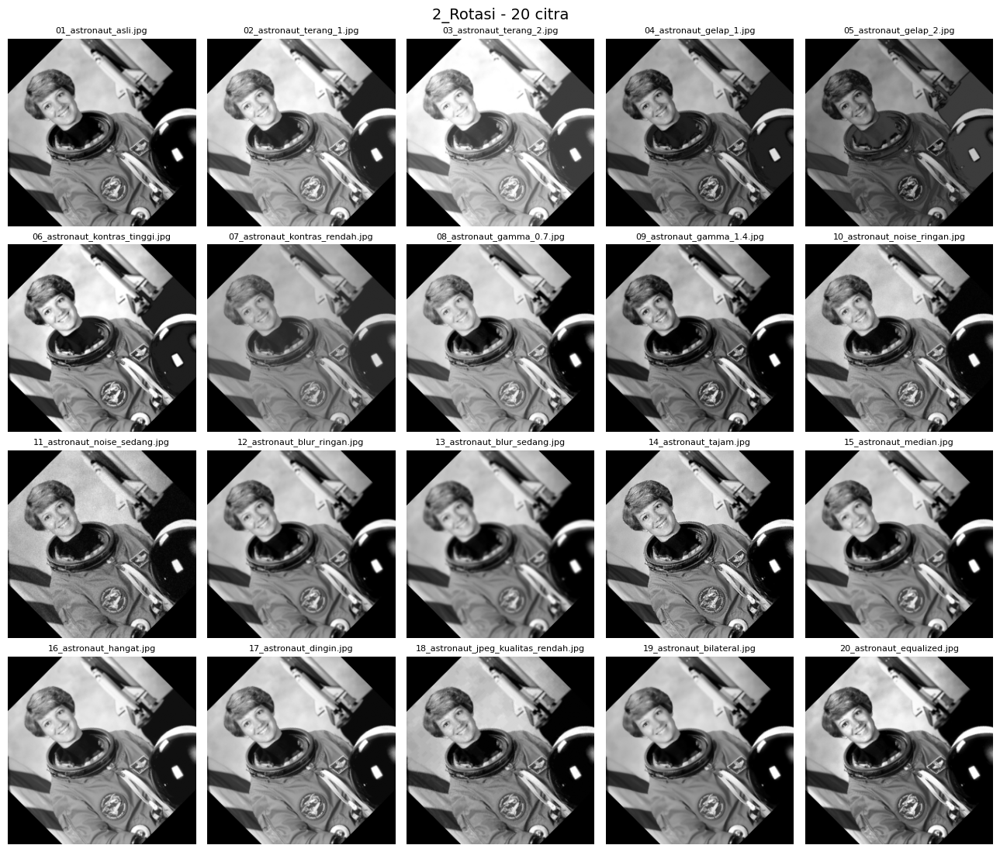

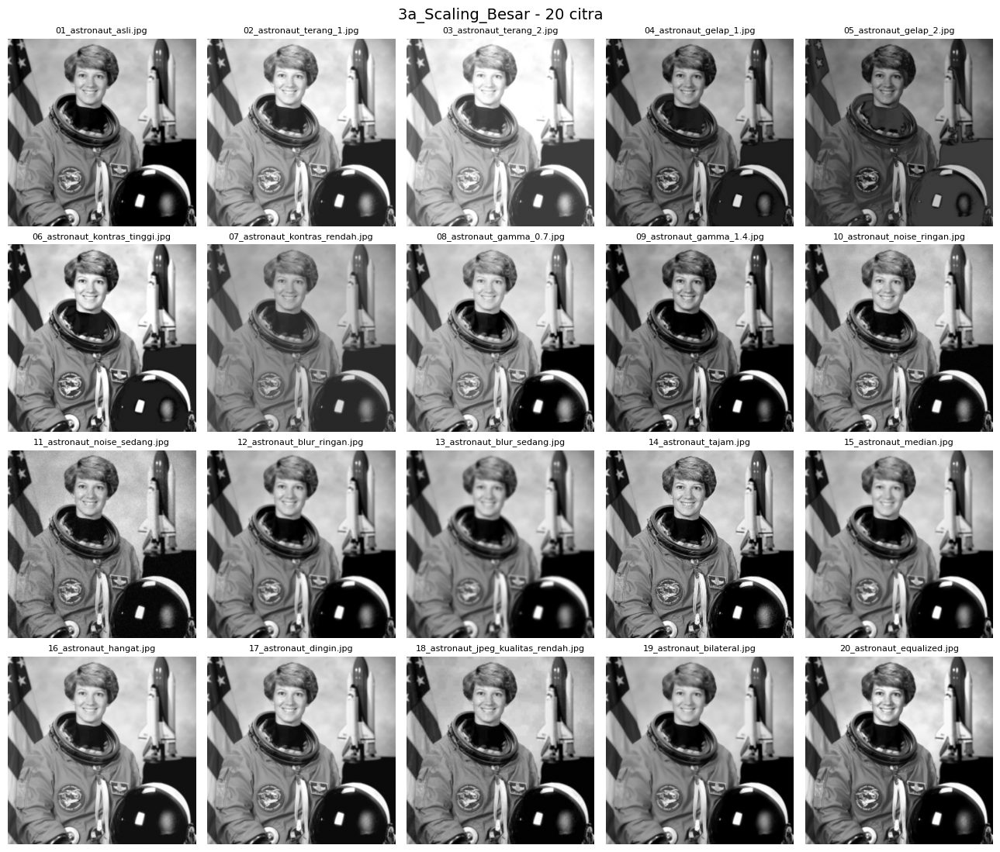

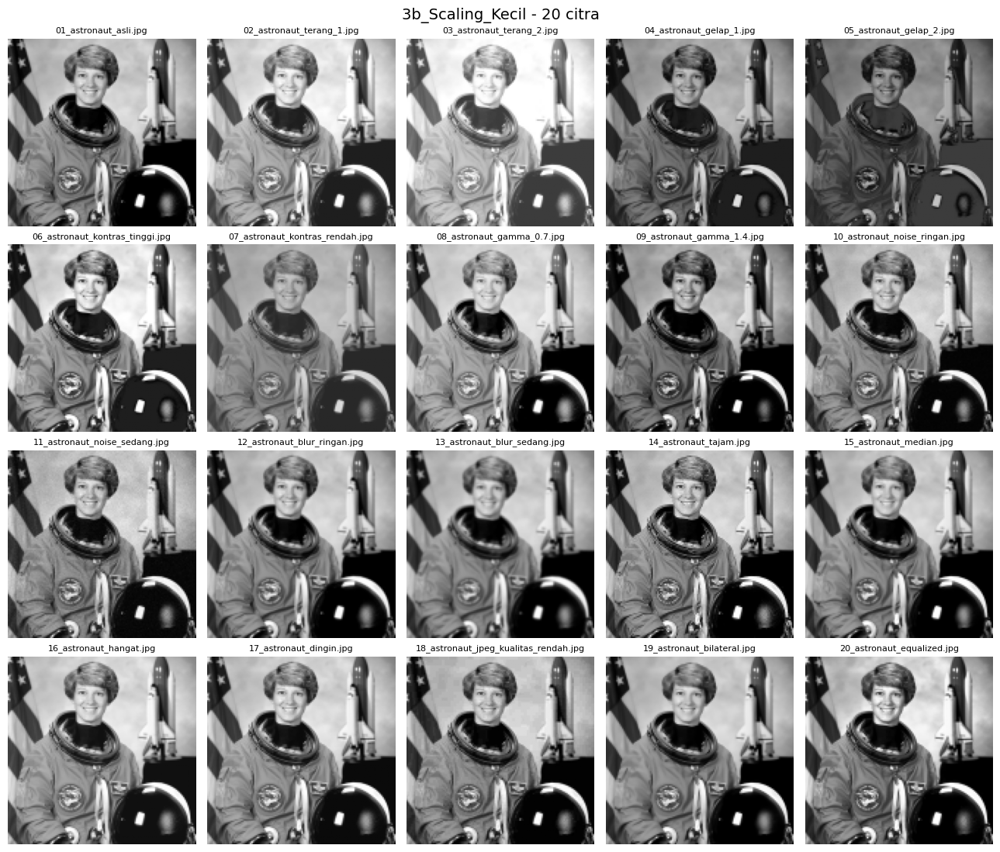

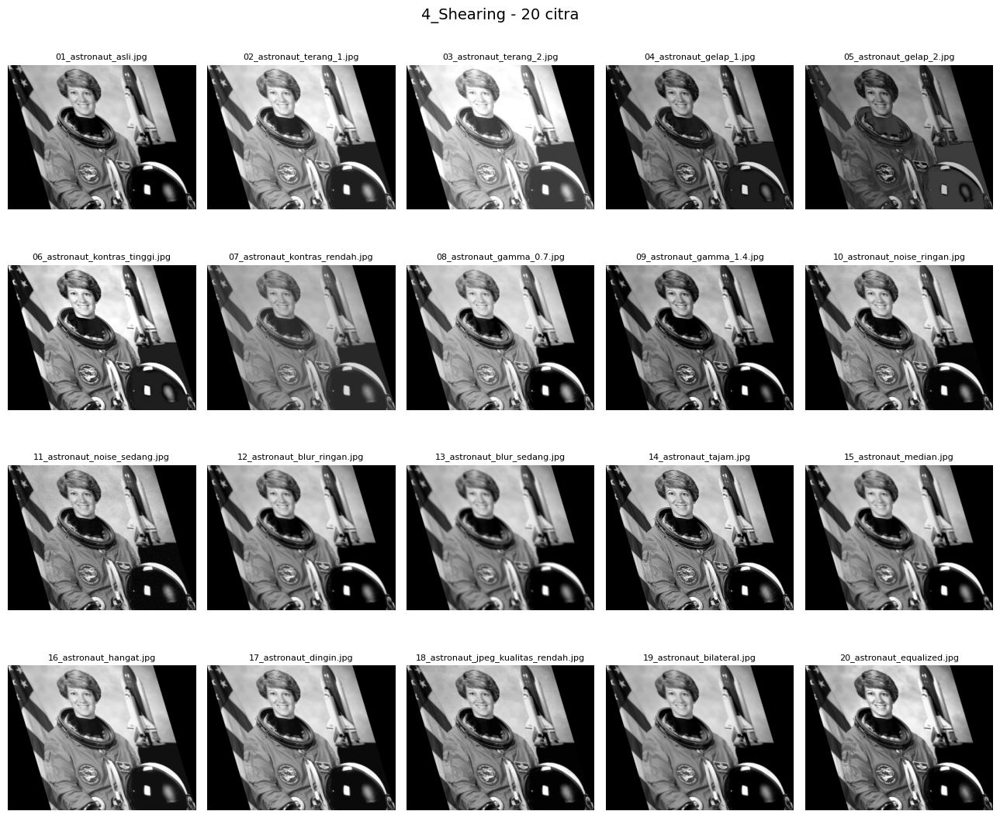

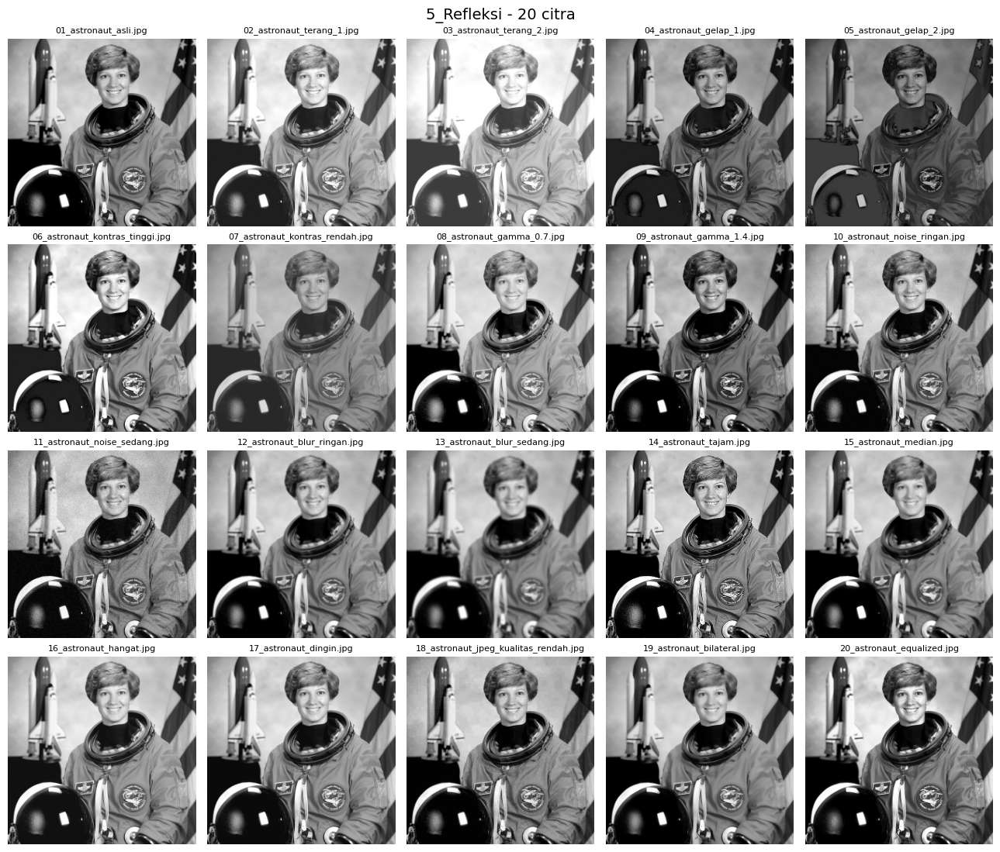

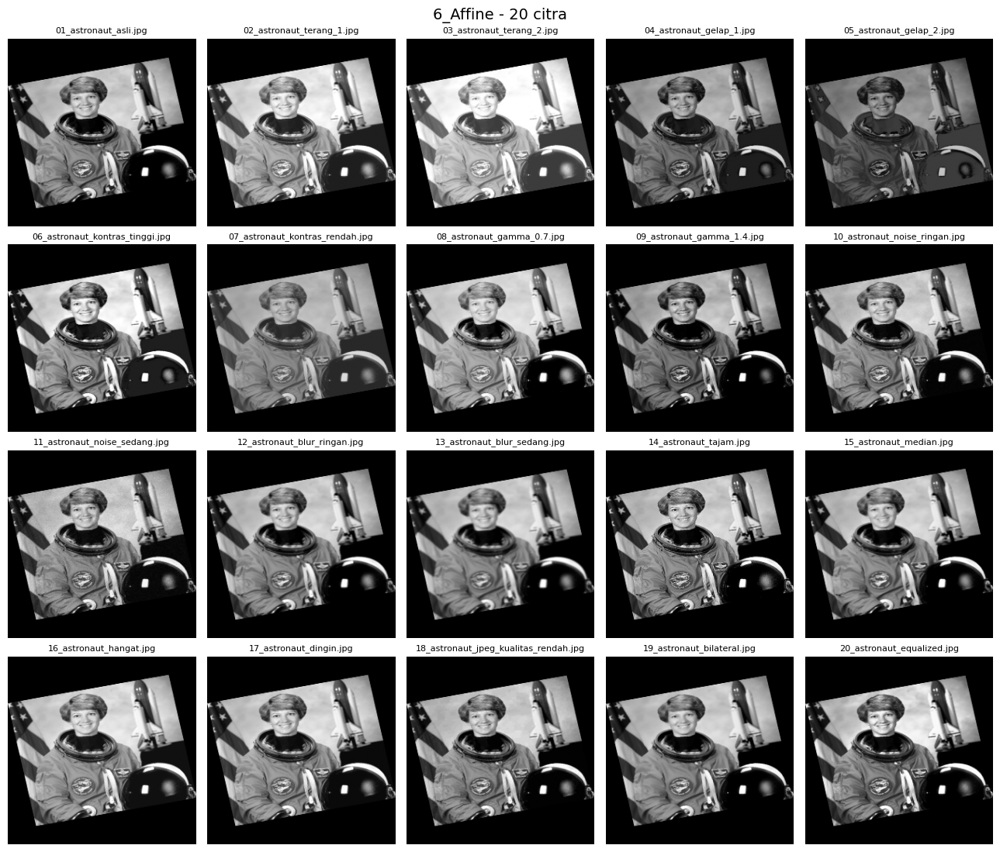

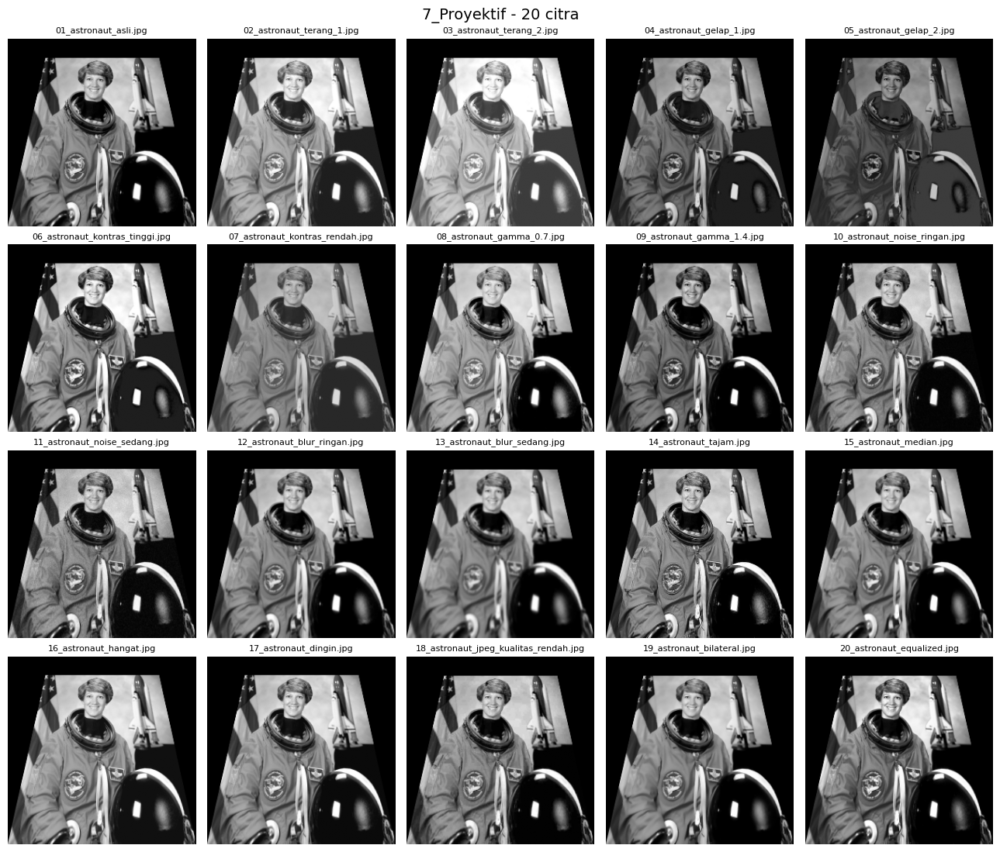

In [63]:
for jenis in semua_hasil[dataset[0][0]]:
    tampilkan_per_transformasi(dataset, semua_hasil, jenis)

## 8. Kesimpulan
- **Translasi, rotasi, refleksi** mempertahankan bentuk dan ukuran objek (transformasi rigid).
- **Scaling** mengubah ukuran citra; **shearing** memiringkan citra sehingga kanvas melebar.
- **Affine** (3 titik) mempertahankan kesejajaran garis, sedangkan **proyektif** (4 titik) tidak, sehingga dapat meniru perubahan sudut pandang kamera.
- Bagian kosong akibat transformasi diisi nilai 0 (hitam).